## Test Plots 

In [1]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ----------------------------
# Config (EDIT THIS)
# ----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change this
POLICIES = ["aggressive", "idle", "dqn", "random"]#,"qrdqn"]
POWERS = [5, 10, 15, 20]

# Jam detection
JAM_THRESHOLD = 0.999   # you can tune; 0.995 or 0.99 might be better depending on your metric
TOLERANCE_STEPS = 5     # merge_asof tolerance


# ----------------------------
# Helpers
# ----------------------------
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Return DataFrame(step, value) for a scalar tag from a tfevents file."""
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)


def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    """
    policy_dir/
      test_dir_name/
        run_dir/
          events.out.tfevents....
    Returns first (largest) event file found.
    """
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None

    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None

    # In your structure there is typically 1 run folder
    # but we search them all to be safe.
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))

    if not candidates:
        return None

    # pick the biggest file (usually the full one)
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


def merge_latency_prb(lat_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align latency and effective_ratio by nearest step."""
    lat_df = lat_df.rename(columns={"value": "latency_sec"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        lat_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["latency_ms"] = df["latency_sec"] * 1000.0  # seconds -> ms (correct if latency is in seconds)
    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_latency_during_jam(event_file: Path) -> float:
    """Compute mean URLLC latency (ms) during jammed samples."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan

    df = merge_latency_prb(lat, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    print("lent(jam(file)):", len(jam_df) )
    return float(jam_df["latency_ms"].mean())



def mean_latency_overall(event_file: Path) -> float:
    """Mean URLLC latency (ms) across all samples (jam + no-jam)."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    if df.empty:
        return np.nan
    return float(df["latency_ms"].mean())


def mean_latency_no_jam(event_file: Path) -> float:
    """Mean URLLC latency (ms) during non-jammed samples only."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    nojam_df = df[~df["jammed"]]
    if nojam_df.empty:
        return np.nan
    return float(nojam_df["latency_ms"].mean())


def merge_throughput_prb(thr_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align eMBB throughput and effective_ratio by nearest step."""
    thr_df = thr_df.rename(columns={"value": "embb_mbps"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        thr_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_embb_throughput_during_jam(event_file: Path) -> float:
    """Compute mean eMBB throughput (Mbps) during jammed samples."""
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if thr.empty or prb.empty:
        return np.nan

    df = merge_throughput_prb(thr, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["embb_mbps"].mean())


def mean_reserve_used_prb_during_jam(event_file: Path) -> float:
    """
    Mean reserve used PRBs (obs/reserve_used_prb) during jammed samples.
    """
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if rsv.empty or prb.empty:
        return np.nan

    rsv = rsv.rename(columns={"value": "reserve_used_prb"}).sort_values("step")
    prb = prb.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        rsv, prb,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["reserve_used_prb"].mean())



2026-01-22 21:55:04.813792: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-22 21:55:04.846163: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-22 21:55:05.583517: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
rows = []
rows_lat = []
rows_thr = []
rows_prb = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            rows.append({
                "policy": policy,
                "jam_prb": pwr,
                "lat_mean_all_ms": np.nan,
                "lat_mean_jam_ms": np.nan,
                "lat_mean_nojam_ms": np.nan,
                "event_file": None
            })
            rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": np.nan, "event_file": None})
            rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": np.nan, "event_file": None})
            rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": np.nan})
            continue

        rows.append({
            "policy": policy,
            "jam_prb": pwr,
            "lat_mean_all_ms": mean_latency_overall(ev_file),
            "lat_mean_jam_ms": mean_latency_during_jam(ev_file),
            "lat_mean_nojam_ms": mean_latency_no_jam(ev_file),
            "event_file": str(ev_file)
        })
        m1 = mean_latency_during_jam(ev_file)
        rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": m1, "event_file": str(ev_file)})
        m2 = mean_embb_throughput_during_jam(ev_file)
        rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": m2, "event_file": str(ev_file)})
        m3 = mean_reserve_used_prb_during_jam(ev_file)
        rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": m3})




df_lat = pd.DataFrame(rows_lat)
df_prb = pd.DataFrame(rows_prb)
df_thr = pd.DataFrame(rows_thr)
df = pd.DataFrame(rows)


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950


In [3]:
# Give each policy a unique linestyle+marker.
# (Colors are left to matplotlib’s default cycle.)
STYLE = {
    "aggressive": dict(linestyle="-",  marker="o"),
    "idle":       dict(linestyle="--", marker="s"),
    "dqn":        dict(linestyle="-.", marker="^"),
    "random":     dict(linestyle=":",  marker="D"),
    "qrdqn":      dict(linestyle=(0, (3, 1, 1, 1)), marker="v"),  # optional
}

DEFAULT_STYLE = dict(linestyle="-", marker="o")


In [19]:
def find_event_file_direct(dir_with_events: Path) -> Path | None:
    """Find the biggest tfevents file directly inside this directory."""
    if not dir_with_events.exists():
        return None
    candidates = list(dir_with_events.glob("events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]

def mean_embb_throughput_overall(event_file: Path) -> float:
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    if thr.empty:
        return np.nan
    return float(thr["value"].mean())

def mean_reserve_used_prb_overall(event_file: Path) -> float:
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    if rsv.empty:
        return np.nan
    return float(rsv["value"].mean())

# --- Baseline (idle no-jam) ---
idle_dir = ROOT / "idle__20260120_092923__res18_off0_const0_per2500_dur1250/"
#baseline_test_name = "gym_from_testing_config_1ms_10s_8UE_jam_fixed_baseline_0"
idle_baseline_ev = find_event_file_direct(idle_dir)

baseline_lat_ms = np.nan
baseline_thr_mbps = np.nan
baseline_rsv_prb = np.nan

if idle_baseline_ev is not None:
    baseline_lat_ms = mean_latency_overall(idle_baseline_ev)  # or mean_latency_no_jam(idle_baseline_ev)
    baseline_thr_mbps = mean_embb_throughput_overall(idle_baseline_ev)
    baseline_rsv_prb = mean_reserve_used_prb_overall(idle_baseline_ev)


In [20]:
#print("baseline_test_name =", baseline_test_name)
print("idle_dir =", idle_dir)
print("idle_baseline_ev =", idle_baseline_ev)


idle_dir = ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250
idle_baseline_ev = ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250/events.out.tfevents.1768919363.elahe-LEGION-T7-34IAS10.985059.0


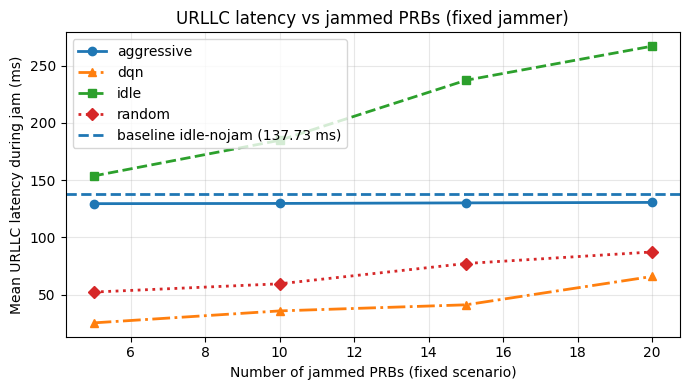

In [21]:
plt.figure(figsize=(7, 4))

for policy, g in df_lat.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_latency_ms"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

# baseline horizontal line
if np.isfinite(baseline_lat_ms):
    plt.axhline(
        baseline_lat_ms,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_lat_ms:.2f} ms)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


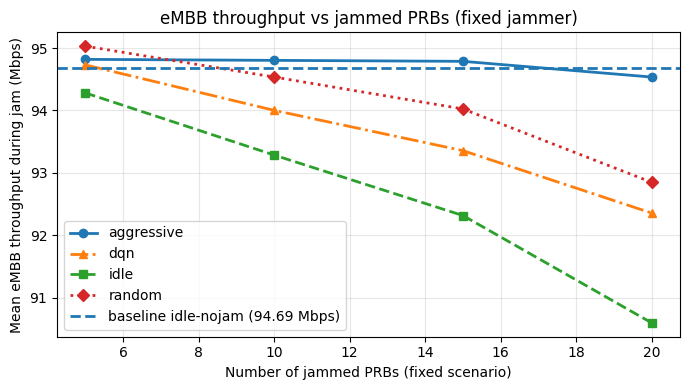

In [22]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_embb_mbps"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_thr_mbps):
    plt.axhline(
        baseline_thr_mbps,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_thr_mbps:.2f} Mbps)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


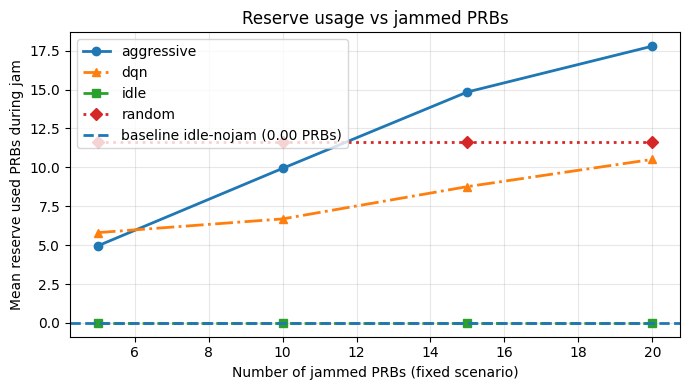

In [23]:
plt.figure(figsize=(7, 4))

for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["reserve_used_prb_mean"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_rsv_prb):
    plt.axhline(
        baseline_rsv_prb,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_rsv_prb:.2f} PRBs)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
def find_event_file_anywhere(root: Path, test_dir_name: str) -> Path | None:
    # finds .../<test_dir_name>/<run_dir>/events.out.tfevents.*
    candidates = list(root.glob(f"**/{test_dir_name}/*/events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]

idle_baseline_ev = find_event_file_anywhere(ROOT, baseline_test_name)
print("idle_baseline_ev (global search) =", idle_baseline_ev)


idle_baseline_ev (global search) = ../../tb_logs/res_validator/random/gym_from_testing_config_1ms_10s_8UE_jam_fixed_baseline_0/random__20260122_093410__res18_off0_const0_per-1_dur0/events.out.tfevents.1769092450.elahe-LEGION-T7-34IAS10.1091859.0


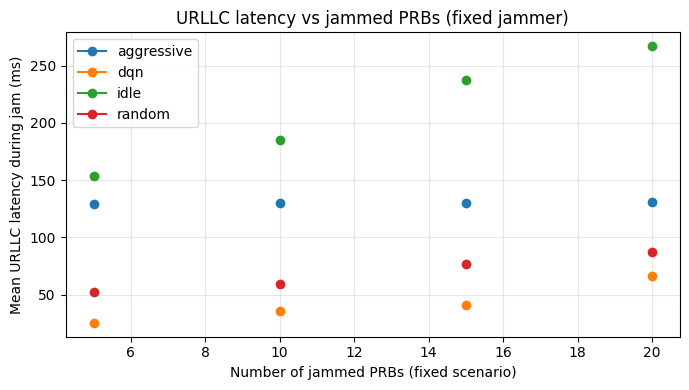

In [7]:
plt.figure(figsize=(7, 4))

for policy, g in df.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_latency_ms"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


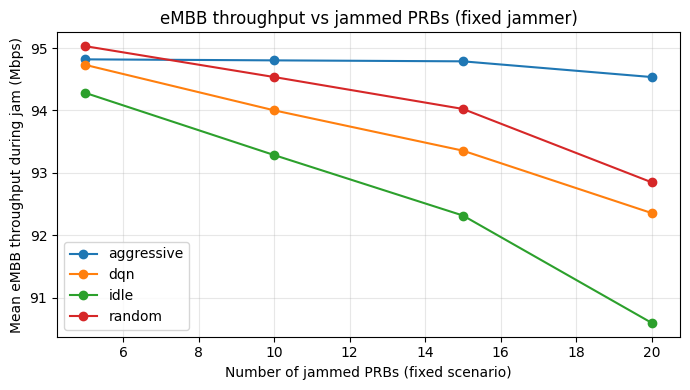

In [8]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_embb_mbps"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


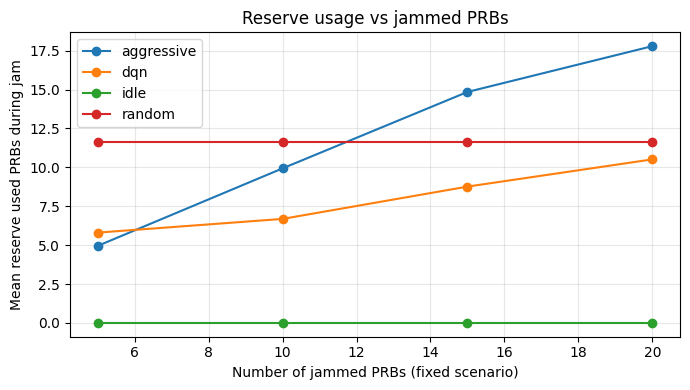

In [9]:
plt.figure(figsize=(7,4))
for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["reserve_used_prb_mean"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


[INFO] Indexing event files under: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator
[INFO] aggressive: 9 event files found
[INFO] idle: 9 event files found
[INFO] dqn: 9 event files found
[INFO] random: 9 event files found
[1/16] policy=aggressive pattern=fixed      -> loading events.out.tfevents.1769113418.elahe-LEGION-T7-34IAS10.1104750.0
[2/16] policy=aggressive pattern=increasing -> loading events.out.tfevents.1769116561.elahe-LEGION-T7-34IAS10.1106150.0
[3/16] policy=aggressive pattern=decreasing -> loading events.out.tfevents.1769110265.elahe-LEGION-T7-34IAS10.1103158.0
[4/16] policy=aggressive pattern=random     -> loading events.out.tfevents.1769119732.elahe-LEGION-T7-34IAS10.1109338.0
[5/16] policy=idle       pattern=fixed      -> loading events.out.tfevents.1769114978.elahe-LEGION-T7-34IAS10.1105370.0
[6/16] policy=idle       pattern=increasing -> loading events.out.tfevents.1769118129.elahe-LEGION-T7-34IAS10.1107508.0
[7/16] policy=idle  

/tmp/ipykernel_1113248/2720928440.py:296: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")


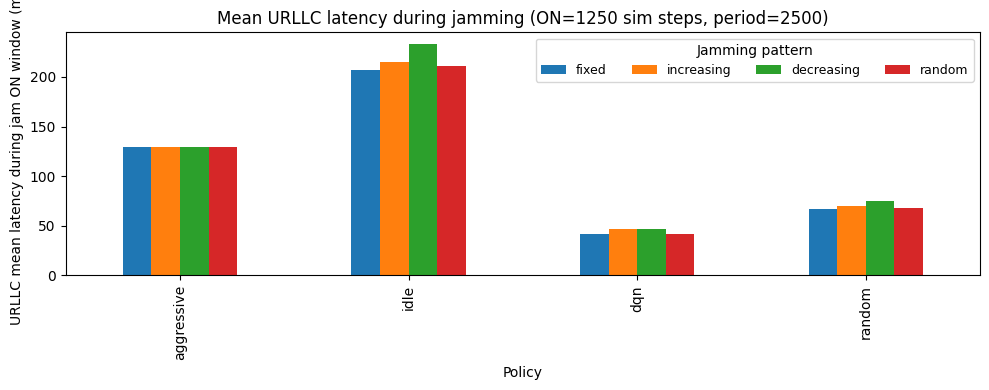

/tmp/ipykernel_1113248/2720928440.py:305: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")


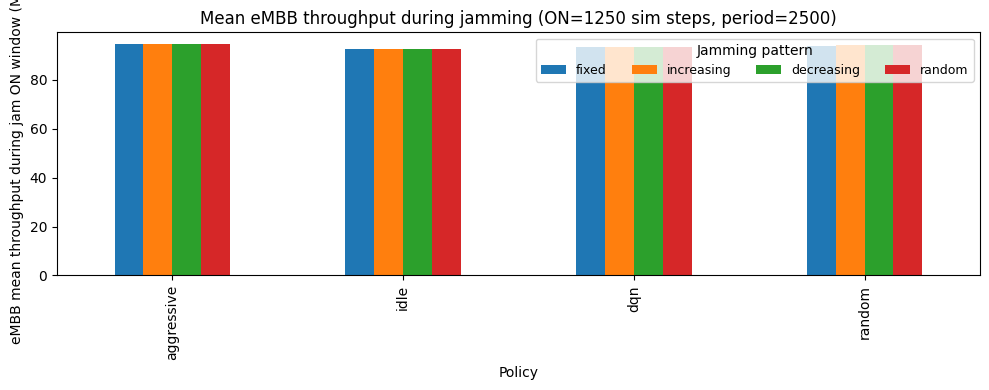


[OK] Saved CSV + plots to: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/_plots


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [11]:
#!/usr/bin/env python3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator

# -----------------------------
# User settings
# -----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "random"]#, "qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

JAM_THRESHOLD = 0.999
DEADLINE_MS = 1.0

# Your jammer (SIM steps)
JAM_ON_STEPS_SIM = 1250
JAM_PERIOD_STEPS_SIM = 2500

PRE_STEPS = 0
POST_EXTRA = 0

# -----------------------------
# Helpers
# -----------------------------
def infer_tb_step_stride(steps: np.ndarray) -> int:
    if steps is None or len(steps) < 3:
        return 1
    d = np.diff(np.asarray(steps, dtype=int))
    d = d[d > 0]
    if len(d) == 0:
        return 1
    return max(1, int(np.median(d)))

def sim_to_tb_steps(sim_steps: int, tb_stride: int) -> int:
    return int(np.ceil(sim_steps / float(tb_stride)))

def merge_asof_by_step(base: pd.DataFrame, other: pd.DataFrame, tolerance: int) -> pd.DataFrame:
    if other is None or other.empty:
        return base
    a = base.sort_values("step").copy()
    b = other.sort_values("step").copy()
    merged = pd.merge_asof(a, b, on="step", direction="nearest", tolerance=tolerance, suffixes=("", "_y"))
    if "wall_time_y" in merged.columns and "wall_time" in merged.columns:
        merged.drop(columns=["wall_time_y"], inplace=True)
    return merged

def detect_jam_starts(df: pd.DataFrame, min_gap_tb_steps: int) -> list[int]:
    if df.empty or "effective_prb_ratio" not in df.columns:
        return []
    steps = df["step"].to_numpy(dtype=int)
    jammed = (df["effective_prb_ratio"].to_numpy() < JAM_THRESHOLD).astype(np.int32)

    starts = []
    prev = 0
    last_start_step = -10**18
    for i in range(len(jammed)):
        if jammed[i] == 1 and prev == 0:
            s0 = int(steps[i])
            if s0 - last_start_step >= min_gap_tb_steps:
                starts.append(s0)
                last_start_step = s0
        prev = jammed[i]
    return starts

def event_aligned_mean_by_index(df: pd.DataFrame, col: str, start_steps: list[int], pre: int, post: int) -> pd.DataFrame:
    if df.empty or col not in df.columns or not start_steps:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    d = df[["step", col]].dropna().sort_values("step").reset_index(drop=True)
    if d.empty:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    steps = d["step"].to_numpy(dtype=int)
    vals = d[col].to_numpy(dtype=float)

    t_rels = np.arange(-pre, post, dtype=int)
    aligned = []

    for s0 in start_steps:
        i0 = int(np.searchsorted(steps, s0))
        if i0 >= len(steps):
            i0 = len(steps) - 1
        if i0 > 0 and abs(steps[i0] - s0) > abs(steps[i0 - 1] - s0):
            i0 -= 1

        row = []
        for tr in t_rels:
            i = i0 + tr
            row.append(vals[i] if (0 <= i < len(vals)) else np.nan)
        aligned.append(row)

    A = np.asarray(aligned, dtype=float)

    n = np.sum(np.isfinite(A), axis=0)
    mean = np.full(A.shape[1], np.nan)
    std  = np.full(A.shape[1], np.nan)

    ok = n > 0
    if np.any(ok):
        mean[ok] = np.nanmean(A[:, ok], axis=0)
        std[ok]  = np.nanstd(A[:, ok], axis=0)

    return pd.DataFrame({"t_rel": t_rels, "mean": mean, "std": std, "n": n})

# -----------------------------
# FAST: index event files once
# -----------------------------
def index_event_files_by_policy(root: Path, policies: list[str]) -> dict[str, list[Path]]:
    """
    Returns: policy -> list of event files under that policy (one rglob per policy)
    """
    out = {}
    for pol in policies:
        pdir = root / pol
        if not pdir.exists():
            out[pol] = []
            continue
        evs = list(pdir.rglob("events.out.tfevents.*"))
        # newest first
        evs.sort(key=lambda p: p.stat().st_mtime, reverse=True)
        out[pol] = evs
    return out

def find_event_file_from_index(index: dict[str, list[Path]], policy: str, test_name: str) -> Path | None:
    """
    Uses pre-indexed list. Just scans the list in memory (fast).
    """
    for ev in index.get(policy, []):
        if test_name in str(ev.parent):
            return ev
    return None

# -----------------------------
# FAST: read all tags from ONE Reload
# -----------------------------
def read_scalars_once(event_file: Path, tags: list[str]) -> dict[str, pd.DataFrame]:
    """
    One EventAccumulator Reload, then pull all requested tags.
    Returns dict tag -> DataFrame(step, wall_time, value)
    """
    ea = event_accumulator.EventAccumulator(str(event_file), size_guidance={"scalars": 0})
    ea.Reload()

    available = set(ea.Tags().get("scalars", []))
    out = {}
    for tag in tags:
        if tag not in available:
            out[tag] = pd.DataFrame(columns=["step", "wall_time", "value"])
            continue
        evs = ea.Scalars(tag)
        df = pd.DataFrame(
            {"step": [e.step for e in evs], "wall_time": [e.wall_time for e in evs], "value": [e.value for e in evs]}
        ).sort_values("step")
        out[tag] = df
    return out

def load_one_run_fast(event_file: Path) -> pd.DataFrame | None:
    tags = ["latency/urllc", "throughput/embb_mbps", "prb/effective_ratio", "obs/reserve_used_prb"]
    scal = read_scalars_once(event_file, tags)

    lat = scal["latency/urllc"].rename(columns={"value": "latency_sec"})
    thr = scal["throughput/embb_mbps"].rename(columns={"value": "embb_mbps"})
    prb = scal["prb/effective_ratio"].rename(columns={"value": "effective_prb_ratio"})
    rsv = scal["obs/reserve_used_prb"].rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None

    tb_stride = infer_tb_step_stride(prb["step"].to_numpy())
    tolerance = max(1, tb_stride // 2)

    df = prb.copy()
    df = merge_asof_by_step(df, lat, tolerance=tolerance)
    df = merge_asof_by_step(df, thr, tolerance=tolerance)
    if not rsv.empty:
        df = merge_asof_by_step(df, rsv, tolerance=tolerance)
    else:
        df["reserve_used_prb"] = np.nan

    df["latency_ms"] = df["latency_sec"] * 1000.0
    df["tb_stride"] = tb_stride
    return df

# -----------------------------
# Main
# -----------------------------
print(f"[INFO] Indexing event files under: {ROOT.resolve()}")
ev_index = index_event_files_by_policy(ROOT, POLICIES)
for pol in POLICIES:
    print(f"[INFO] {pol}: {len(ev_index.get(pol, []))} event files found")

aligned_lat = {}
aligned_thr = {}
aligned_eff = {}
summary_rows = []

total_jobs = len(POLICIES) * len(PATTERNS)
job_i = 0

for policy in POLICIES:
    for pat in PATTERNS:
        job_i += 1
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file_from_index(ev_index, policy, test_name)

        print(f"[{job_i}/{total_jobs}] policy={policy:<10} pattern={pat:<10} -> ", end="")
        if ev is None:
            print("NO EVENT FILE")
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": None,
            })
            continue

        print(f"loading {ev.name}")

        df = load_one_run_fast(ev)
        if df is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": str(ev),
            })
            continue

        tb_stride = int(df["tb_stride"].iloc[0])
        jam_on_tb = sim_to_tb_steps(JAM_ON_STEPS_SIM, tb_stride)
        period_tb = sim_to_tb_steps(JAM_PERIOD_STEPS_SIM, tb_stride)

        PRE_TB = PRE_STEPS
        POST_TB = period_tb + POST_EXTRA
        MIN_GAP_TB = max(1, period_tb - 1)

        starts = detect_jam_starts(df, min_gap_tb_steps=MIN_GAP_TB)

        lat_al = event_aligned_mean_by_index(df, "latency_ms", starts, pre=PRE_TB, post=POST_TB)
        thr_al = event_aligned_mean_by_index(df, "embb_mbps", starts, pre=PRE_TB, post=POST_TB)
        eff_al = event_aligned_mean_by_index(df, "effective_prb_ratio", starts, pre=PRE_TB, post=POST_TB)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary during jam ON window [0, jam_on_tb)
        if not lat_al.empty:
            s = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_lat_ms = float(np.nanmean(s)) if len(s) else np.nan
            violation_pct = float(np.mean(s > DEADLINE_MS) * 100.0) if len(s) else np.nan
        else:
            jam_lat_ms = np.nan
            violation_pct = np.nan

        if not thr_al.empty:
            s = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_thr_mbps = float(np.nanmean(s)) if len(s) else np.nan
        else:
            jam_thr_mbps = np.nan

        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if not jam_df.empty else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "tb_stride": tb_stride,
            "jam_on_tb_steps": jam_on_tb,
            "period_tb_steps": period_tb,
            "jam_lat_ms": jam_lat_ms,
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr_mbps,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df["policy"] = pd.Categorical(summary_df["policy"], categories=POLICIES, ordered=True)
summary_df["pattern"] = pd.Categorical(summary_df["pattern"], categories=PATTERNS, ordered=True)

print("\n=== Summary (head) ===")
print(summary_df.head(10))
print("\n=== Summary (full) ===")
print(summary_df)

# -----------------------------
# Bar charts
# -----------------------------
lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")
ax = lat_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")
ax = thr_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

# Save outputs
OUT_DIR = ROOT / "_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(OUT_DIR / "summary_latency_throughput.csv", index=False)

plt.figure(figsize=(10, 4))
ax = lat_pivot.plot(kind="bar")
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_latency_ms.png", dpi=200)
plt.close()

plt.figure(figsize=(10, 4))
ax = thr_pivot.plot(kind="bar")
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_throughput_mbps.png", dpi=200)
plt.close()

print(f"\n[OK] Saved CSV + plots to: {OUT_DIR.resolve()}")


## Training Plots

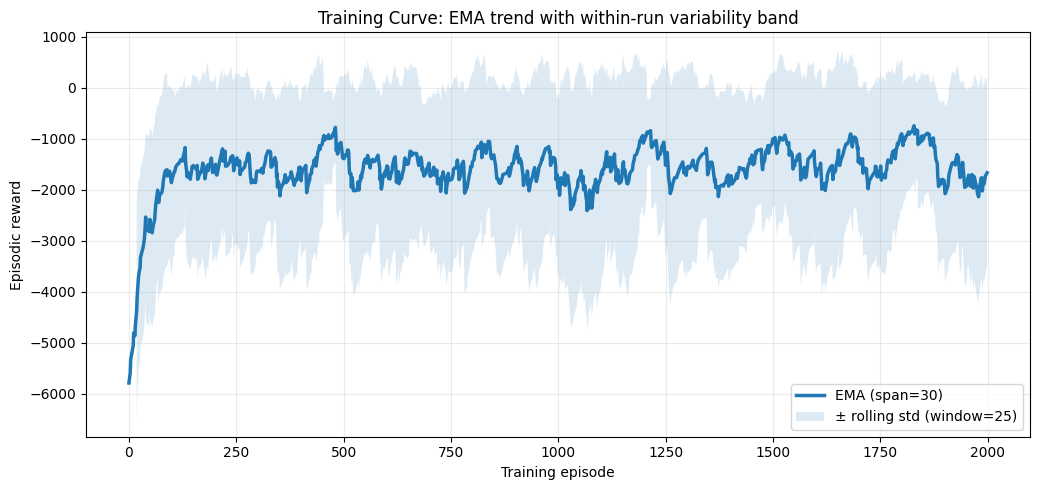

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Optional: clip extreme negative spikes for visualization only
q_low = df["reward"].quantile(0.05)       # bottom 5%
r = df["reward"].clip(lower=q_low)

# --- Trend line: EMA
ema_span = max(10, int(len(df) * 0.03))
ema = r.ewm(span=ema_span, adjust=False).mean()

# --- Variability band: rolling std around the EMA (within-run volatility)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()

# Sometimes std can be NaN at the beginning; mask those
valid = ~roll_std.isna()

plt.figure(figsize=(10.5, 5))
#plt.plot(x, r.to_numpy(), linewidth=1, alpha=0.20, label="Raw episodic reward (clipped)")
plt.plot(x, ema.to_numpy(), linewidth=2.5, label=f"EMA (span={ema_span})")

# Shaded band: EMA ± rolling std
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    alpha=0.15,
    label=f"± rolling std (window={band_w})"
)

plt.xlabel("Episode" if use_episode_index else "Training episode")
plt.ylabel("Episodic reward")
plt.title("Training Curve: EMA trend with within-run variability band")
plt.grid(True, alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


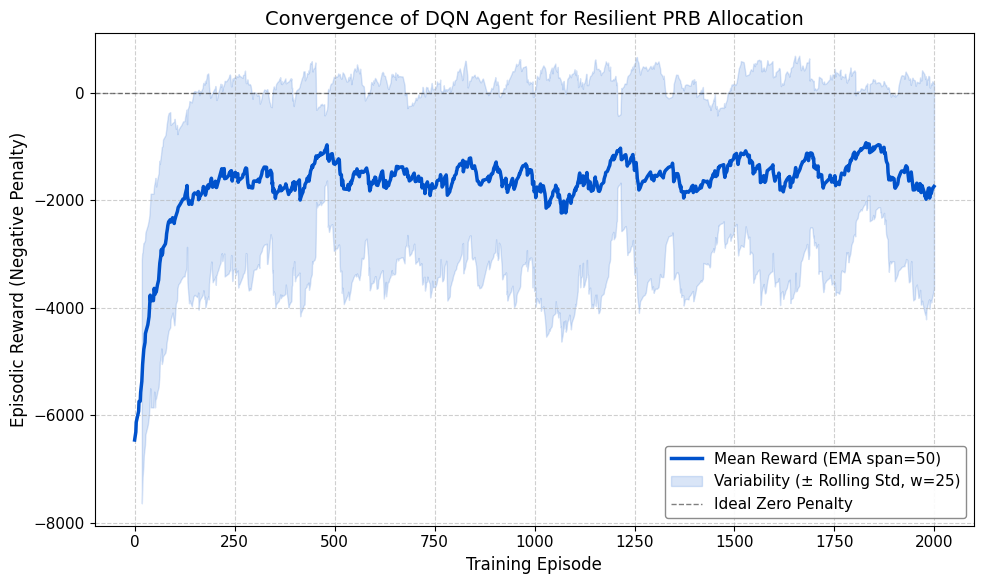

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Load Data ---
csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

# --- X-Axis Handling ---
# Paper mentions 40,000 episodes[cite: 256]. 
# Ensure 'step' corresponds to what you want to show (Episodes vs Steps).
use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Data Smoothing ---
# 1. Clip extreme outliers (bottom 1%) to remove startup noise while keeping failures visible
q_low = df["reward"].quantile(0.01) 
r = df["reward"].clip(lower=q_low)

# 2. EMA Trend
# Increased span slightly to make the trend clearer for the paper
ema_span = max(10, int(len(df) * 0.05)) 
ema = r.ewm(span=ema_span, adjust=False).mean()

# 3. Variability band (Rolling STD)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()
valid = ~roll_std.isna()

# --- Plotting Style for Paper ---
# Setting global font sizes to ensure readability when the image is resized in a PDF
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16
})

plt.figure(figsize=(10, 6))

# Main EMA Line (Thicker for visibility)
plt.plot(x, ema.to_numpy(), color='#0052cc', linewidth=2.5, label=f"Mean Reward (EMA span={ema_span})")

# Variability Band (Lighter blue)
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    color='#0052cc',
    alpha=0.15,
    label=f"Variability (± Rolling Std, w={band_w})"
)

# Optional: Add a baseline at 0 (Perfect Score)
plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5, label="Ideal Zero Penalty")

# Labels and Title based on your paper context
plt.xlabel("Training Episode")
plt.ylabel("Episodic Reward (Negative Penalty)")
plt.title("Convergence of DQN Agent for Resilient PRB Allocation")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor='gray')
plt.tight_layout()

# Save high-res for paper
plt.savefig("training_convergence.pdf", dpi=300) 
plt.show()